# Lab04. Обучаем LoRA в Google Colab

Цель: научить Qwen3-0.6B предсказывать оценку автора отзыва от 1 до 5.
Основная модель остается замороженной, обучаются только матрицы LoRA.

Нужен **облачный GPU Colab**: меню **Среда выполнения → Сменить среду выполнения → T4 GPU**
или другой доступный GPU. Затем выполняйте ячейки сверху вниз.
Не подключайте локальную среду выполнения. Первая ячейка останавливает запуск вне облачного Colab и без CUDA.

Одна эпоха: 5000 отзывов, по 1000 на оценку, 625 групп по 8 примеров.
Все данные и веса скачиваются в облачную машину. Веса Qwen в архив результатов не входят.

Этот файл содержит код эксперимента. Результаты появятся в выводах после реального запуска;
заранее заданных значений ошибки или качества здесь нет.

[Задание](https://github.com/pmenshih/tgo-course/blob/main/assignments/04/README.md) ·
[Qwen](https://huggingface.co/Qwen/Qwen3-0.6B) ·
[Данные](https://huggingface.co/datasets/mteb/GeoreviewClassification)

## 1. Проверяем место запуска

Сначала проверяем облачную среду, затем GPU. Проверка выполняется до установки библиотек,
загрузки модели и обучения. CPU и MPS не используются как запасной вариант.

In [8]:
import os
from pathlib import Path

if not os.environ.get("COLAB_RELEASE_TAG") or not Path("/content").is_dir():
    raise RuntimeError("Запуск разрешен только в облачном Google Colab. Локальная среда не подходит.")
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Выберите GPU в настройках среды Colab и перезапустите выполнение.")
print("Облачный GPU:", torch.cuda.get_device_name(0))
print("Память GPU, ГБ:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

Облачный GPU: Tesla T4
Память GPU, ГБ: 15.64


## 2. Устанавливаем библиотеки

Версии библиотек зафиксированы. Установленный в Colab PyTorch сохраняем: он связан с CUDA этой среды.
Если Colab попросит перезапустить сеанс после установки, перезапустите его и снова выполните ячейки сверху вниз.

In [9]:
import subprocess, sys
REQUIREMENTS = ['transformers==4.57.1', 'peft==0.17.1', 'datasets==4.3.0', 'accelerate==1.11.0', 'safetensors==0.6.2', 'matplotlib==3.10.7']
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *REQUIREMENTS], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.1', 'peft==0.17.1', 'datasets==4.3.0', 'accelerate==1.11.0', 'safetensors==0.6.2', 'matplotlib==3.10.7'], returncode=0)

## 3. Фиксируем условия эксперимента

Ранг LoRA равен 8, alpha равна 16. Для одной матрицы 1024 × 1024 полное изменение потребовало бы
1 048 576 параметров, а две матрицы 1024 × 8 и 8 × 1024 содержат 16 384 параметра.
Это иллюстрация для одной матрицы; фактическое число параметров всех адаптеров посчитаем ниже.

Эффективный батч 8 разбит на четыре части по 2 отзыва. После каждой части считаем градиенты,
а веса обновляем один раз после всех восьми отзывов. Так уменьшаем необходимую память GPU.

In [10]:
import csv, hashlib, json, math, random, time, zipfile
from collections import Counter
from datetime import datetime, timezone
import importlib.metadata
import matplotlib.pyplot as plt
from datasets import load_dataset, load_from_disk
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
from safetensors.torch import load_file

MODEL = "Qwen/Qwen3-0.6B"
MODEL_REVISION = "c1899de289a04d12100db370d81485cdf75e47ca"
DATASET = "mteb/GeoreviewClassification"
DATASET_REVISION = "fb29d6137c54550329411023aee45a8ff29f0c62"
SEED, MAX_LEN, BATCH, MICRO_BATCH = 42, 256, 8, 2
EPOCHS, LR, WEIGHT_DECAY = 1, 2e-4, 0.01
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cuda.matmul.allow_tf32 = False
WORK = Path("/content/mtusi-lab04")
ARTIFACTS = WORK / "lab04" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = "/content/huggingface-cache"
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

def save_json(name, value):
    path = ARTIFACTS / name
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporary.replace(path)

print("GPU:", torch.cuda.get_device_name(0), "тип чисел:", DTYPE)
print("Каталог результатов:", ARTIFACTS)

GPU: Tesla T4 тип чисел: torch.float16
Каталог результатов: /content/mtusi-lab04/lab04/artifacts


## 4. Выбираем те же 5000 обучающих отзывов

Выбираем без повторов по 1000 отзывов каждого класса из `train`, seed = 42.
`validation` и `test` в обучение не попадают. Контрольная сумма проверяет совпадение
с ранее подготовленными обучающими данными. Метка набора `0..4` переводится в звезды `1..5`.

In [11]:
def balanced_indices(labels, per_class, seed):
    """Выбор без повторов; один проход по меткам и фиксированный генератор."""
    if per_class < 1:
        raise ValueError("Число примеров каждого класса должно быть положительным")
    groups = [[] for _ in range(5)]
    for idx, label in enumerate(labels):
        if label not in range(5):
            raise ValueError("Метка вне диапазона 0..4")
        groups[label].append(idx)
    rng = random.Random(seed)
    selected = []
    for label, indices in enumerate(groups):
        if len(indices) < per_class:
            raise ValueError(f"Для оценки {label + 1} нужно {per_class} примеров, есть {len(indices)}")
        selected.extend(rng.sample(indices, per_class))
    rng.shuffle(selected)
    return selected

def selection_digest(rows):
    digest = hashlib.sha256()
    for row in rows:
        record = json.dumps([row["text"], int(row["label"])], ensure_ascii=False)
        digest.update((record + "\n").encode("utf-8"))
    return digest.hexdigest()

local_data = os.environ.get("LAB_DATA")
dataset = load_from_disk(local_data) if local_data else load_dataset(DATASET, revision=DATASET_REVISION)
train_indices = balanced_indices(dataset["train"]["label"], 1000, SEED)
train_rows = dataset["train"].select(train_indices)
train_sha = selection_digest(train_rows)
assert len(train_rows) == 5000 and len(set(train_indices)) == 5000
assert Counter(train_rows["label"]) == Counter({i: 1000 for i in range(5)})
assert train_sha == "4fee30649d353a04bb985a91e4630b53aaaa7a1d369d05a32cea5a0f829fc671", "Обучающая выборка изменилась"
print("Отзывов:", len(train_rows), "оценки:", {i + 1: 1000 for i in range(5)})
print("SHA256 выбранных текстов и оценок:", train_sha)

Отзывов: 5000 оценки: {1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000}
SHA256 выбранных текстов и оценок: 4fee30649d353a04bb985a91e4630b53aaaa7a1d369d05a32cea5a0f829fc671


## 5. Сохраняем прежний запрос

Инструкция и формат вопроса совпадают с zero-shot. При обучении к запросу дописываем правильную
цифру и маркер конца ответа. Готовые примеры в запрос не добавляем: здесь знания должны попасть в адаптер.

In [12]:
import re

SYSTEM_PROMPT = (
    "Определи, какую оценку от 1 до 5 поставил автор отзыва об организации. "
    "Шкала: 1 - очень плохо, 2 - плохо, 3 - удовлетворительно, "
    "4 - хорошо, 5 - отлично. Ответь одной цифрой от 1 до 5 без объяснений."
)

def review_message(text):
    return f"Отзыв:\n{text}\n\nКакую оценку поставил автор? Ответь одной цифрой от 1 до 5."

def zero_shot_messages(text):
    # Функция получает только текст: правильной оценки здесь нет.
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": review_message(text)}]

def parse_rating(answer):
    """Принимаем единственное отдельное целое число, если оно от 1 до 5."""
    numbers = re.findall(r"(?<![\w.,])[+-]?\d+(?:[.,]\d+)?(?!\w)", answer)
    if len(numbers) == 1 and numbers[0] in ("1", "2", "3", "4", "5"):
        return int(numbers[0])
    return None

tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=MODEL_REVISION)
tokenizer.padding_side = "right"

## 6. Считаем ошибку только по ответу

В `input_ids` находятся запрос и правильный ответ. В `labels` все позиции запроса заменены на `-100`:
они не участвуют в функции потерь. Целями остаются цифра и маркер конца сообщения.
Сдвиг целей на один токен выполняет сама модель.

Если текст длиннее лимита, сокращаем только отзыв. Инструкция, начало ответа, цифра и маркер конца
должны сохраниться. Проверяем это для всех 5000 примеров до загрузки весов.

In [13]:
def make_training_example(tokenizer, text, stars, max_len=256):
    if stars not in range(1, 6):
        raise ValueError("Правильная оценка должна быть от 1 до 5")
    end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")
    if end_id is None or end_id == tokenizer.unk_token_id:
        raise ValueError("У токенизатора нет маркера конца сообщения Qwen")
    answer_ids = tokenizer.encode(str(stars), add_special_tokens=False) + [end_id]

    def prompt_ids(review):
        rendered = tokenizer.apply_chat_template(
            zero_shot_messages(review), tokenize=False,
            add_generation_prompt=True, enable_thinking=False,
        )
        return tokenizer.encode(rendered, add_special_tokens=False)

    original_ids = tokenizer.encode(text, add_special_tokens=False)
    prefix = prompt_ids(text)
    kept = len(original_ids)
    if len(prefix) + len(answer_ids) > max_len:
        budget = max_len - len(answer_ids) - len(prompt_ids(""))
        if budget < 1:
            raise ValueError("В заданную длину не помещаются инструкция и ответ")
        kept = min(kept, budget)
        while True:
            shortened = tokenizer.decode(original_ids[:kept], skip_special_tokens=False)
            prefix = prompt_ids(shortened)
            excess = len(prefix) + len(answer_ids) - max_len
            if excess <= 0:
                break
            kept -= max(1, excess)
            if kept < 1:
                raise ValueError("Не удалось сохранить отзыв в заданной длине")
    ids = prefix + answer_ids
    labels = [-100] * len(prefix) + answer_ids
    assert len(ids) == len(labels) <= max_len
    assert all(value == -100 for value in labels[:len(prefix)])
    assert labels[len(prefix):] == answer_ids and labels[-1] == end_id
    return {
        "input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels,
        "prompt_length": len(prefix), "answer_ids": answer_ids,
        "review_truncated": kept < len(original_ids),
    }

def pad_training_batch(examples, pad_id):
    """Возвращает списки, чтобы маски можно было проверить без torch."""
    if not examples:
        raise ValueError("Пустой батч")
    size = max(len(row["input_ids"]) for row in examples)
    batch = {key: [] for key in ("input_ids", "attention_mask", "labels")}
    for row in examples:
        padding = size - len(row["input_ids"])
        batch["input_ids"].append(row["input_ids"] + [pad_id] * padding)
        batch["attention_mask"].append(row["attention_mask"] + [0] * padding)
        batch["labels"].append(row["labels"] + [-100] * padding)
    return batch

encoded = [make_training_example(tokenizer, row["text"], row["label"] + 1, MAX_LEN) for row in train_rows]
assert all(len(row["answer_ids"]) == 2 for row in encoded)
assert all(sum(label != -100 for label in row["labels"]) == 2 for row in encoded)
sample = encoded[0]
print("Первый отзыв:", train_rows[0]["text"][:180])
print("Правильная оценка:", train_rows[0]["label"] + 1)
print("Токенов запроса:", sample["prompt_length"], "всего:", len(sample["input_ids"]))
print("Позиции с ошибкой:", [(i, tokenizer.decode([label])) for i, label in enumerate(sample["labels"]) if label != -100])
print("Сокращено длинных отзывов:", sum(row["review_truncated"] for row in encoded))
save_json("training_example.json", {"input_ids": sample["input_ids"], "labels": sample["labels"],
                                   "prompt_length": sample["prompt_length"], "answer_ids": sample["answer_ids"]})

Первый отзыв: В основном приезжаю если нужно срочно анализ крови .Здесь общий анализ крови делают за 5 мин. Биохимия от часа и т. д. Так же можно сделать УЗИ, эхо сердца и т. Д. Оборудование ест
Правильная оценка: 2
Токенов запроса: 254 всего: 256
Позиции с ошибкой: [(254, '2'), (255, '<|im_end|>')]
Сокращено длинных отзывов: 1910


## 7. Загружаем Qwen и добавляем LoRA

К семи типам линейных слоев добавляются обучаемые матрицы. Для исходного преобразования `Wx`
теперь вычисляется `Wx + (alpha / r) BAx`. Меняются только `A` и `B`.
Проверяем, что список обучаемых параметров состоит из LoRA и их доля меньше 2%.

In [14]:
assert torch.cuda.is_available(), "Облачная GPU отключилась"
base = AutoModelForCausalLM.from_pretrained(MODEL, revision=MODEL_REVISION, dtype=DTYPE).to("cuda")
model = get_peft_model(base, LoraConfig(
    r=8, lora_alpha=16, target_modules=TARGET_MODULES,
    lora_dropout=0.0, bias="none", task_type="CAUSAL_LM",
))
model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()
trainable = [(name, p) for name, p in model.named_parameters() if p.requires_grad]
assert trainable and all("lora_" in name for name, p in trainable)
trainable_params = sum(p.numel() for name, p in trainable)
total_params = sum(p.numel() for p in model.parameters())
assert trainable_params / total_params < 0.02
frozen_versions = {name: p._version for name, p in model.named_parameters() if not p.requires_grad}
adapter_before = {name: p.detach().cpu().clone() for name, p in trainable}
TRAINING_STARTED = False
print("Обучаемых параметров:", f"{trainable_params:,}")
print("Всего с адаптером:", f"{total_params:,}")
print("Доля обучаемых:", f"{100 * trainable_params / total_params:.3f}%")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Обучаемых параметров: 5,046,272
Всего с адаптером: 601,096,192
Доля обучаемых: 0.840%


## 8. Обучаем одну эпоху

Оптимизатор получает только параметры LoRA. На каждой группе из восьми отзывов считаем ошибку,
градиенты и одно обновление. Вывод каждые 25 шагов показывает среднюю ошибку за этот интервал.
Шаг 0 показывает ошибку на восьми фиксированных обучающих отзывах до обучения.

Текущий адаптер сохраняется каждые 100 шагов в облачную папку `checkpoint_adapter`.
Это промежуточные веса, а не полный снимок оптимизатора для точного продолжения.
Финальные артефакты записываются после всей эпохи. Повтор этой ячейки запрещен без перезапуска
модели: так случайный повтор не превратит одну эпоху в две.

In [15]:
if globals().get("TRAINING_STARTED", False):
    raise RuntimeError("Обучение уже запускалось. Для нового эксперимента выполните ноутбук заново с ячейки загрузки модели.")
TRAINING_STARTED = True
assert len(encoded) % BATCH == 0 and BATCH % MICRO_BATCH == 0
order = torch.randperm(len(encoded), generator=torch.Generator().manual_seed(SEED)).tolist()

def tensor_batch(indices):
    values = pad_training_batch([encoded[i] for i in indices], tokenizer.pad_token_id)
    return {key: torch.tensor(value, dtype=torch.long, device="cuda") for key, value in values.items()}

def probe_loss():
    model.eval()
    values = []
    with torch.inference_mode(), torch.autocast("cuda", dtype=DTYPE):
        for start in range(0, BATCH, MICRO_BATCH):
            values.append(float(model(**tensor_batch(order[start:start + MICRO_BATCH])).loss))
    model.train()
    return sum(values) / len(values)

optimizer = torch.optim.AdamW([p for name, p in trainable], lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=(DTYPE == torch.float16), init_scale=1024)
initial_probe = probe_loss()
curve = [{"step": 0, "loss": initial_probe}]
config = {
    "model": MODEL, "model_revision": MODEL_REVISION, "dataset": DATASET,
    "dataset_revision": DATASET_REVISION, "train_sha256": train_sha,
    "lora_r": 8, "lora_alpha": 16, "target_modules": TARGET_MODULES,
    "trainable_params": trainable_params, "total_params": total_params,
    "trainable_pct": 100 * trainable_params / total_params,
    "train_examples": len(encoded), "epochs": EPOCHS, "steps": 0,
    "batch": BATCH, "micro_batch": MICRO_BATCH, "lr": LR, "weight_decay": WEIGHT_DECAY,
    "max_len": MAX_LEN, "train_minutes": 0.0, "peak_memory_gb": 0.0,
    "device": "cuda", "gpu": torch.cuda.get_device_name(0), "dtype": str(DTYPE), "seed": SEED,
    "training_status": "running", "skipped_updates": 0,
    "truncated_reviews": sum(row["review_truncated"] for row in encoded),
    "loss_policy": "Prompt and padding labels are -100; rating token and end-of-message token are supervised",
    "curve_policy": "step 0: fixed eight training examples; later: mean training loss since previous measurement",
    "timing_policy": "Training loop with logging and checkpoint saves; excludes downloads, preparation and initial/final probes",
    "versions": {name: importlib.metadata.version(name) for name in ["torch", "transformers", "peft", "datasets", "accelerate"]},
}
save_json("train_config.json", config)
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
started = time.perf_counter()
interval_losses = []
with (ARTIFACTS / "train_log.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=["step", "loss"], lineterminator="\n")
    writer.writeheader(); writer.writerow(curve[0]); stream.flush()
    for step, start in enumerate(range(0, len(order), BATCH), 1):
        optimizer.zero_grad(set_to_none=True)
        group_loss = 0.0
        for offset in range(0, BATCH, MICRO_BATCH):
            indices = order[start + offset:start + offset + MICRO_BATCH]
            with torch.autocast("cuda", dtype=DTYPE):
                loss = model(**tensor_batch(indices)).loss
            if not torch.isfinite(loss):
                raise RuntimeError(f"Неконечная ошибка на шаге {step}")
            group_loss += float(loss.detach()) / (BATCH // MICRO_BATCH)
            scaler.scale(loss / (BATCH // MICRO_BATCH)).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_([p for name, p in trainable], 1.0)
        old_scale = scaler.get_scale()
        scaler.step(optimizer); scaler.update()
        if scaler.get_scale() < old_scale:
            config["skipped_updates"] += 1
        interval_losses.append(group_loss)
        if step % 100 == 0:
            model.save_pretrained(WORK / "checkpoint_adapter", safe_serialization=True)
        if step % 25 == 0 or step == len(order) // BATCH:
            point = {"step": step, "loss": sum(interval_losses) / len(interval_losses)}
            curve.append(point); writer.writerow(point); stream.flush(); interval_losses.clear()
            config.update(steps=step, train_minutes=(time.perf_counter() - started) / 60,
                          peak_memory_gb=torch.cuda.max_memory_allocated() / 1e9)
            save_json("train_config.json", config)
            print(f"Шаг {step}/625: loss={point['loss']:.4f}, {config['train_minutes']:.2f} мин", flush=True)
torch.cuda.synchronize()
config["train_minutes"] = (time.perf_counter() - started) / 60
config["peak_memory_gb"] = torch.cuda.max_memory_allocated() / 1e9
config["applied_updates"] = config["steps"] - config["skipped_updates"]
config["probe_loss_before"] = initial_probe
config["probe_loss_after"] = probe_loss()
config["training_status"] = "completed"
save_json("train_config.json", config)
print("Эпоха завершена; применено обновлений:", config["applied_updates"])

Шаг 25/625: loss=0.7744, 0.94 мин
Шаг 50/625: loss=0.7016, 1.78 мин
Шаг 75/625: loss=0.6033, 2.61 мин
Шаг 100/625: loss=0.6072, 3.46 мин
Шаг 125/625: loss=0.5747, 4.28 мин
Шаг 150/625: loss=0.5812, 5.10 мин
Шаг 175/625: loss=0.5915, 5.92 мин
Шаг 200/625: loss=0.5576, 6.76 мин
Шаг 225/625: loss=0.5600, 7.59 мин
Шаг 250/625: loss=0.5604, 8.43 мин
Шаг 275/625: loss=0.5113, 9.27 мин
Шаг 300/625: loss=0.5788, 10.11 мин
Шаг 325/625: loss=0.5357, 10.94 мин
Шаг 350/625: loss=0.5389, 11.77 мин
Шаг 375/625: loss=0.5104, 12.60 мин
Шаг 400/625: loss=0.5084, 13.43 мин
Шаг 425/625: loss=0.5406, 14.27 мин
Шаг 450/625: loss=0.5367, 15.10 мин
Шаг 475/625: loss=0.5821, 15.92 мин
Шаг 500/625: loss=0.5482, 16.75 мин
Шаг 525/625: loss=0.5466, 17.58 мин
Шаг 550/625: loss=0.5227, 18.41 мин
Шаг 575/625: loss=0.5256, 19.24 мин
Шаг 600/625: loss=0.5276, 20.06 мин
Шаг 625/625: loss=0.4914, 20.86 мин
Эпоха завершена; применено обновлений: 625


## 9. Проверяем и сохраняем адаптер

Проверяем, что основные веса остались прежними, а LoRA изменилась. Сохраняем только адаптер,
сверяем число параметров в файле и строим график по фактическому журналу.
Падение обучающей ошибки еще не доказывает качество на новых отзывах.

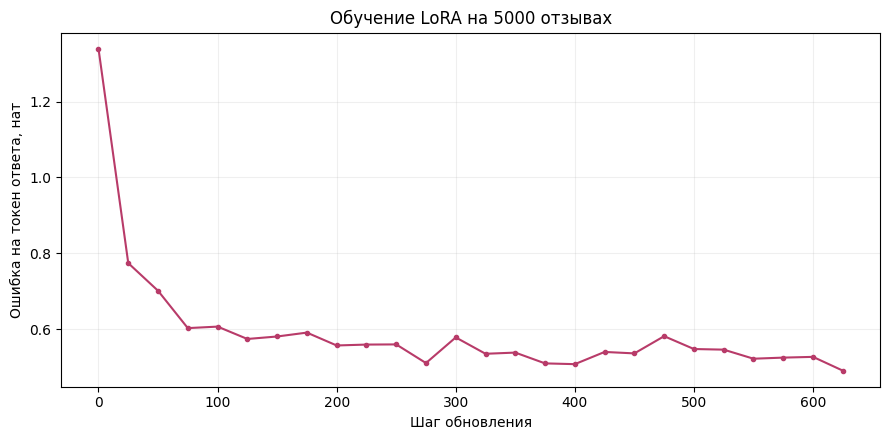

Средняя ошибка первых замеров: 0.805144842641428
Средняя ошибка последних замеров: 0.522791469251737
Фиксированный учебный батч до/после: 1.3391200602054596 0.6754343584179878
Обучение, минут: 20.864754554699996 пиковая память тензоров CUDA, ГБ: 2.255115264


In [16]:
assert config["steps"] == 625 and config["applied_updates"] > 0
assert frozen_versions == {name: p._version for name, p in model.named_parameters() if not p.requires_grad}
changed = sum(not torch.equal(adapter_before[name], p.detach().cpu()) for name, p in trainable)
assert changed > 0, "Матрицы адаптера не изменились"
adapter_path = ARTIFACTS / "adapter"
model.save_pretrained(adapter_path, safe_serialization=True)
weights = load_file(adapter_path / "adapter_model.safetensors", device="cpu")
assert sum(value.numel() for value in weights.values()) == trainable_params
assert all(torch.isfinite(value).all() for value in weights.values())
config["frozen_weights_unchanged"] = True
config["changed_adapter_tensors"] = changed
config["adapter_sha256"] = hashlib.sha256((adapter_path / "adapter_model.safetensors").read_bytes()).hexdigest()
save_json("train_config.json", config)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot([p["step"] for p in curve], [p["loss"] for p in curve], color="#b83b69", marker=".")
ax.set(title="Обучение LoRA на 5000 отзывах", xlabel="Шаг обновления", ylabel="Ошибка на токен ответа, нат")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS / "train_curve.png", dpi=150)
plt.show()
k = max(1, len(curve) // 5)
print("Средняя ошибка первых замеров:", sum(p["loss"] for p in curve[:k]) / k)
print("Средняя ошибка последних замеров:", sum(p["loss"] for p in curve[-k:]) / k)
print("Фиксированный учебный батч до/после:", config["probe_loss_before"], config["probe_loss_after"])
print("Обучение, минут:", config["train_minutes"], "пиковая память тензоров CUDA, ГБ:", config["peak_memory_gb"])

## 10. Смотрим ответы после обучения

Проверяем те же первые три отзыва из `test`, которые разбирали раньше. Модель получает только отзыв,
без примеров. Правильная оценка нужна только для последующего сравнения.
Три примера дают предварительную проверку, но не заменяют оценку на 1000 отзывах.

In [17]:
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()
preview = []
for idx in range(3):
    row = dataset["test"][idx]
    prompt = tokenizer.apply_chat_template(zero_shot_messages(row["text"]), tokenize=False,
                                          add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").to("cuda")
    with torch.inference_mode():
        generated = model.generate(**inputs, do_sample=False, max_new_tokens=3,
                                   temperature=None, top_p=None, top_k=None,
                                   pad_token_id=tokenizer.pad_token_id)
    ids = generated[0, inputs["input_ids"].shape[1]:].tolist()
    raw = tokenizer.decode(ids, skip_special_tokens=True)
    prediction = parse_rating(raw)
    preview.append({"idx": idx, "label": row["label"] + 1, "prediction": prediction, "raw_answer": raw, "ids": ids})
    print(f"Отзыв {idx}: ответ {raw!r}, оценка автора {row['label'] + 1}")
save_json("adapter_preview.json", {"n": 3, "examples": preview, "device": "cuda", "dtype": str(DTYPE)})

Отзыв 0: ответ '1', оценка автора 3
Отзыв 1: ответ '4', оценка автора 4
Отзыв 2: ответ '2', оценка автора 2


## 11. Забираем результаты

Архив содержит адаптер, настройки, журнал, график и предварительные ответы. Он не содержит исходные
отзывы, кеш или веса Qwen. Скачайте также сам ноутбук через **Файл → Скачать → Скачать IPYNB**,
чтобы сохранить выводы ячеек. В настройках Colab сохранение выводов должно быть включено.

Следующий шаг после обучения: оценить адаптер на тех же 1000 отзывах и сравнить все три режима
в облаке. По результатам первых трех примеров параметры обучения не подбираем.

Файлы в `/content` относятся к текущей виртуальной машине и могут исчезнуть после завершения сеанса.
Скачанный архив сохраняет полученный результат независимо от времени жизни этой машины.

In [18]:
archive = WORK / "lab04-colab-results.zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(ARTIFACTS.rglob("*")):
        if path.is_file():
            bundle.write(path, str(path.relative_to(WORK)))
print("Архив, МБ:", round(archive.stat().st_size / 1e6, 2))
from google.colab import files
files.download(str(archive))

Архив, МБ: 18.76


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>